# 02 - GPM IMERG Rainfall

*GPM IMERG Daily Precipitation — Exploratory Data Analysis*

**Field Shift: Adapting Farms with NASA Data**  
NASA GPM IMERG Final Run (`GPM_3IMERGDF V07`) measures satellite-derived precipitation. This GIOVANNI area-average export is daily (mm/day) for Sidi Salem–Qallin, North Nile Delta, Egypt (requested bbox 30.70, 31.05, 30.91, 31.30). The product is natively 0.1° and half-hourly; this export is spatially averaged and daily aggregated. The final common analysis period is strictly January 2016–December 2024.

## 1. Dataset overview and source discovery


In [18]:
from pathlib import Path
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# Run from notebooks/ or from the project root.
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

# Inspect candidate files and select only the file that contains GIOVANNI's time header.
candidates = sorted(ROOT.rglob('*.csv'))
gpm_candidates = []
for candidate in candidates:
    text = candidate.read_text(encoding='utf-8-sig', errors='replace')
    if any(line.strip().lower().startswith('time,') for line in text.splitlines()):
        gpm_candidates.append(candidate)
print('CSV candidates:', [p.relative_to(ROOT).as_posix() for p in candidates])
print('GIOVANNI daily candidates:', [p.relative_to(ROOT).as_posix() for p in gpm_candidates])
assert len(gpm_candidates) == 1, 'Select the cleaned GPM file explicitly if this changes.'
INPUT_FILE = gpm_candidates[0]

raw_text = INPUT_FILE.read_text(encoding='utf-8-sig', errors='replace')
raw_lines = raw_text.splitlines()
header_row = next(i for i, line in enumerate(raw_lines) if line.strip().lower().startswith('time,'))
metadata_lines = raw_lines[:header_row]
source = pd.read_csv(io.StringIO('\n'.join(raw_lines[header_row:])))
print('Input:', INPUT_FILE.relative_to(ROOT))
print('Metadata:', *metadata_lines, sep='\n  ')


CSV candidates: ['data/processed/gpm_monthly.csv', 'gpm_daily_2016_2024.csv.csv']
GIOVANNI daily candidates: ['gpm_daily_2016_2024.csv.csv']
Input: gpm_daily_2016_2024.csv.csv
Metadata:
  Title:,"Time Series, Area-Averaged of Daily mean precipitation rate (combined microwave-IR) estimate - Final (daily)"
  User Start Date:,2016-01-01T00:00:00Z
  User End Date:,2024-12-31T23:59:59Z
  User Bounding Box:,"30.7,31.05,30.91,31.3"
  Data Bounding Box:,"30.75,31.05,30.85,31.25"
  URL to Reproduce Results:,"https://giovanni.gsfc.nasa.gov/giovanni/?utm_source=chatgpt.com#service=ArAvTs&starttime=2016-01-01T00:00:00Z&endtime=2024-12-31T23:59:59Z&bbox=30.7,31.05,30.91,31.3&data=GPM_3IMERGDF_07_precipitation&portal=GIOVANNI&format=json"
  Fill Value (mean_GPM_3IMERGDF_07_precipitation):,-9999.9
  ,


In [19]:
# Actual source columns are time and the GPM precipitation field.
date_col = next(c for c in source.columns if c.strip().lower() == 'time')
rain_col = next(c for c in source.columns if c != date_col)
df = source.rename(columns={date_col: 'date', rain_col: 'rain_mm'}).copy()
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['rain_mm'] = pd.to_numeric(df['rain_mm'], errors='coerce')

# The source metadata declares -9999.9 as a fill value. Preserve it as NaN for analysis;
# never convert missing observations to zero, and do not alter the original file.
fill_value = -9999.9
fill_count = df['rain_mm'].eq(fill_value).sum()
df.loc[df['rain_mm'].eq(fill_value), 'rain_mm'] = np.nan
df = df.sort_values('date').reset_index(drop=True)
EXPECTED_START, EXPECTED_END = pd.Timestamp('2016-01-01'), pd.Timestamp('2024-12-31')
EXPECTED_DAYS = len(pd.date_range(EXPECTED_START, EXPECTED_END, freq='D'))

print('Dimensions:', df.shape)
display(pd.DataFrame({'column': df.columns, 'dtype': df.dtypes.astype(str)}))
display(df.head(), df.tail())
print('Date range:', df.date.min().date(), 'to', df.date.max().date())
print('Unit: mm/day; fill values converted to NaN:', fill_count)


Dimensions: (3288, 2)


,column,dtype
date,date,datetime64[us]
rain_mm,rain_mm,float64


,date,rain_mm
0,2016-01-01,0.077
1,2016-01-02,0.000
2,2016-01-03,0.336
3,2016-01-04,0.000
4,2016-01-05,0.203


,date,rain_mm
3283,2024-12-27,0.863
3284,2024-12-28,0.024
3285,2024-12-29,2.052
3286,2024-12-30,2.815
3287,2024-12-31,0.000


Date range: 2016-01-01 to 2024-12-31
Unit: mm/day; fill values converted to NaN: 0


## 2. Data structure and validation
All checks are reported before aggregation. The code never invents dates or silently fills values.


In [20]:
expected_dates = pd.date_range(EXPECTED_START, EXPECTED_END, freq='D')
missing_dates = expected_dates.difference(pd.DatetimeIndex(df['date'].dropna()))
duplicate_dates = df['date'].duplicated(keep=False)
chronological = df['date'].is_monotonic_increasing
invalid_dates = df['date'].isna().sum()
infinite = np.isinf(df['rain_mm'].to_numpy(dtype=float, na_value=np.nan)).sum()
negative = (df['rain_mm'] < 0).sum()
# A transparent screening threshold, not an automatic exclusion: 100 mm/day is improbable here.
unusually_high = df.loc[df['rain_mm'] > 100, ['date', 'rain_mm']]

checks = pd.DataFrame([
 ['date parsed', invalid_dates == 0, invalid_dates],
 ['rainfall numeric / finite', infinite == 0, infinite],
 ['chronologically sorted', chronological, chronological],
 ['duplicate dates', not duplicate_dates.any(), duplicate_dates.sum()],
 ['missing expected dates', len(missing_dates) == 0, len(missing_dates)],
 ['exact expected coverage', df.date.min() == EXPECTED_START and df.date.max() == EXPECTED_END, f'{df.date.min()} — {df.date.max()}'],
 ['one row per day / expected rows', len(df) == EXPECTED_DAYS and not duplicate_dates.any() and len(missing_dates) == 0, f'{len(df)} / {EXPECTED_DAYS}'],
 ['negative rainfall', negative == 0, negative],
 ['potentially unrealistic >100 mm/day', len(unusually_high) == 0, len(unusually_high)],
], columns=['check','pass','result'])
checks['status'] = np.where(checks['pass'], 'PASS', 'FAIL')
display(checks[['status','check','result']])
if len(missing_dates): print('Missing dates:', missing_dates.strftime('%Y-%m-%d').tolist())
if duplicate_dates.any(): display(df.loc[duplicate_dates].sort_values('date'))
if len(unusually_high): display(unusually_high)
display(pd.DataFrame({'missing_values': df.isna().sum(), 'missing_percent': df.isna().mean().mul(100)}))


,status,check,result
0,PASS,date parsed,0
1,PASS,rainfall numeric / finite,0
2,PASS,chronologically sorted,True
3,PASS,duplicate dates,0
4,PASS,missing expected dates,0
5,PASS,exact expected coverage,2016-01-01 00:00:00 — 2024-12-31 00:00:00
6,PASS,one row per day / expected rows,3288 / 3288
7,PASS,negative rainfall,0
8,PASS,potentially unrealistic >100 mm/day,0


,missing_values,missing_percent
date,0,0.000
rain_mm,0,0.000


## 3. Missing values and data quality
Negative values, non-finite values, declared fill values, and unusually high values are screened. An extreme is not treated as an error merely because it is large.


## 4. Statistical analysis


In [21]:
valid = df['rain_mm'].dropna()
dry = valid.eq(0)
rainy = valid.ge(1)
summary = pd.Series({
    'mean_daily_mm': valid.mean(), 'median_daily_mm': valid.median(), 'std_daily_mm': valid.std(),
    'min_daily_mm': valid.min(), 'max_daily_mm': valid.max(),
    'p25_mm': valid.quantile(.25), 'p50_mm': valid.quantile(.50), 'p75_mm': valid.quantile(.75),
    'p90_mm': valid.quantile(.90), 'p95_mm': valid.quantile(.95),
    'dry_days_n': dry.sum(), 'dry_days_pct': dry.mean()*100,
    'rainy_days_n': rainy.sum(), 'rainy_days_pct': rainy.mean()*100,
    'days_ge_10_mm': valid.ge(10).sum(), 'days_ge_20_mm': valid.ge(20).sum(),
})
display(summary.to_frame('value'))
print('Zero is a valid dry-day measurement; NaN remains missing and is excluded from percentages.')

df['year'], df['month'] = df.date.dt.year, df.date.dt.month
monthly = (df.groupby(['year','month'], as_index=False)
 .agg(rain_mm=('rain_mm', lambda x: x.sum(min_count=1)),
      rain_days=('rain_mm', lambda x: x.ge(1).sum() if x.notna().any() else np.nan),
      max_day_rain_mm=('rain_mm','max')))
monthly['month_start'] = pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
assert len(monthly) == 108 and not monthly.duplicated(['year','month']).any()
assert monthly.year.between(2016, 2024).all()
OUTPUT_FILE = ROOT / 'data' / 'processed' / 'gpm_monthly.csv'
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
monthly[['year','month','rain_mm','rain_days','max_day_rain_mm']].to_csv(OUTPUT_FILE, index=False)
print('Wrote:', OUTPUT_FILE.relative_to(ROOT), 'with', len(monthly), 'rows.')


,value
mean_daily_mm,0.301
median_daily_mm,0.000
std_daily_mm,1.804
min_daily_mm,0.000
max_daily_mm,43.809
p25_mm,0.000
p50_mm,0.000
p75_mm,0.000
p90_mm,0.188
p95_mm,1.050


Zero is a valid dry-day measurement; NaN remains missing and is excluded from percentages.
Wrote: data\processed\gpm_monthly.csv with 108 rows.


## 5. Time-series visualizations


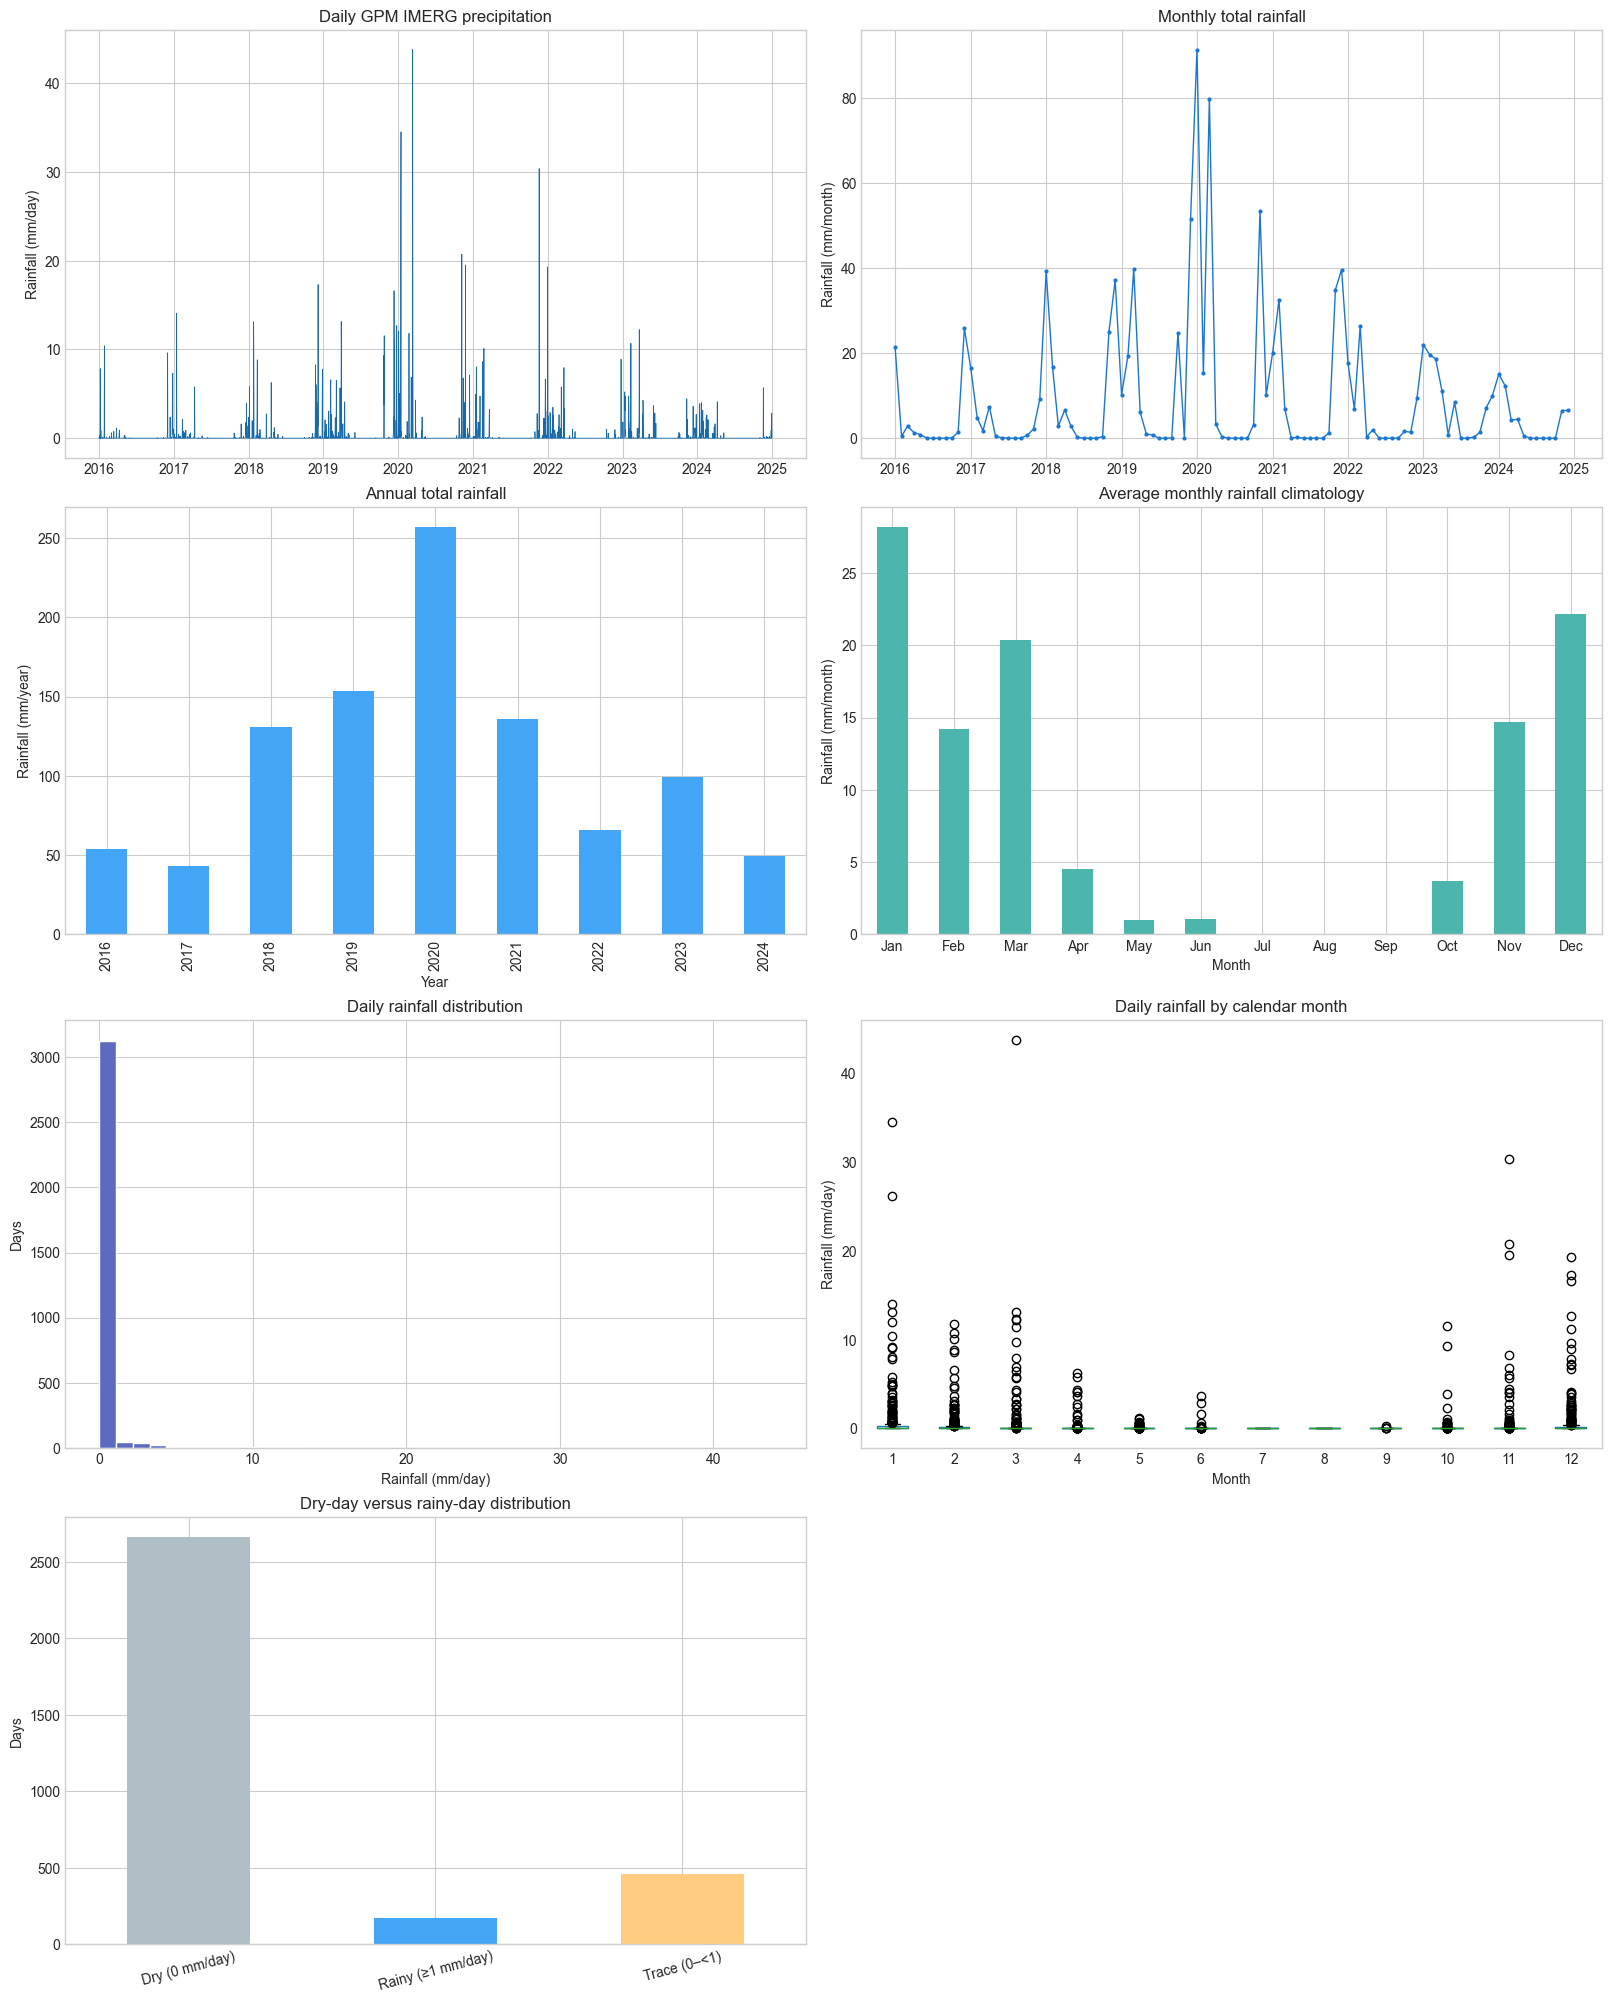

In [22]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20), constrained_layout=True)
ax = axes[0,0]; ax.plot(df.date, df.rain_mm, lw=.55, color='#1769aa'); ax.set(title='Daily GPM IMERG precipitation', ylabel='Rainfall (mm/day)'); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax = axes[0,1]; ax.plot(monthly.month_start, monthly.rain_mm, marker='o', ms=2, lw=1, color='#1976d2'); ax.set(title='Monthly total rainfall', ylabel='Rainfall (mm/month)'); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
annual = df.groupby('year').agg(total_mm=('rain_mm', lambda x: x.sum(min_count=1)), mean_daily_mm=('rain_mm','mean'), rainy_days=('rain_mm',lambda x:x.ge(1).sum()), max_daily_mm=('rain_mm','max'))
ax = axes[1,0]; annual.total_mm.plot.bar(ax=ax, color='#42a5f5'); ax.set(title='Annual total rainfall', xlabel='Year', ylabel='Rainfall (mm/year)')
climatology = monthly.groupby('month').rain_mm.mean(); ax = axes[1,1]; climatology.plot.bar(ax=ax, color='#4db6ac'); ax.set(title='Average monthly rainfall climatology', xlabel='Month', ylabel='Rainfall (mm/month)'); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=0)
ax = axes[2,0]; ax.hist(valid, bins=40, color='#5c6bc0', edgecolor='white'); ax.set(title='Daily rainfall distribution', xlabel='Rainfall (mm/day)', ylabel='Days')
ax = axes[2,1]; df.boxplot(column='rain_mm', by='month', ax=ax, grid=False); ax.set(title='Daily rainfall by calendar month', xlabel='Month', ylabel='Rainfall (mm/day)'); plt.suptitle('')
ax = axes[3,0]; pd.Series({'Dry (0 mm/day)': dry.sum(), 'Rainy (≥1 mm/day)': rainy.sum(), 'Trace (0–<1)': ((valid>0)&(valid<1)).sum()}).plot.bar(ax=ax, color=['#b0bec5','#42a5f5','#ffcc80']); ax.set(title='Dry-day versus rainy-day distribution', ylabel='Days'); ax.tick_params(axis='x', rotation=15)
axes[3,1].axis('off')
plt.show()


## 6. Annual and seasonal analysis
Winter uses the calendar-year convention: December 2020, for example, is winter 2020.


## 7. Extreme rainfall analysis


In [23]:
# Egypt seasonal convention: Dec–Feb winter; December is attributed to its calendar year here.
season_map = {12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'}
df['season'] = df.month.map(season_map)
seasonal = df.groupby(['year','season'], as_index=False).agg(rain_mm=('rain_mm', lambda x:x.sum(min_count=1)))
season_order = ['Winter','Spring','Summer','Autumn']
seasonal['season'] = pd.Categorical(seasonal.season, season_order, ordered=True)
display(annual)
print('Wettest year:', annual.total_mm.idxmax(), annual.total_mm.max())
print('Driest year:', annual.total_mm.idxmin(), annual.total_mm.min())
display(seasonal.sort_values(['year','season']).pivot(index='year', columns='season', values='rain_mm'))

top5 = df.nlargest(5, 'rain_mm')[['date','rain_mm']]
display(top5)
display(monthly.nlargest(5, 'rain_mm')[['year','month','rain_mm']])
reference = df.loc[df.date.eq(pd.Timestamp('2020-03-12')), ['date','rain_mm']]
display(reference)
print('The reference 43.8 mm/day is evaluated from the data above; no event is labelled as a flood without independent evidence.')


,total_mm,mean_daily_mm,rainy_days,max_daily_mm
year,,,,
2016,54.094,0.148,9,10.418
2017,43.067,0.118,8,14.060
2018,130.926,0.359,23,17.318
2019,153.621,0.421,27,16.613
2020,256.805,0.702,21,43.809
2021,135.685,0.372,23,30.386
2022,65.639,0.180,17,8.907
2023,99.314,0.272,26,12.238
2024,49.731,0.136,15,5.686


Wettest year: 2020 256.804781604
Driest year: 2017 43.066806987


season,Winter,Spring,Summer,Autumn
year,,,,
2016,47.589,5.020,0.051,1.434
2017,30.457,9.662,0.090,2.858
2018,92.975,12.292,0.217,25.442
2019,81.193,46.808,0.712,24.907
2020,116.815,83.474,0.003,56.513
2021,92.267,7.210,0.000,36.208
2022,33.961,28.671,0.000,3.007
2023,51.537,30.597,8.418,8.762
2024,33.887,9.325,0.000,6.519


,date,rain_mm
1532,2020-03-12,43.809
1475,2020-01-15,34.524
2150,2021-11-20,30.386
1474,2020-01-14,26.169
1772,2020-11-07,20.751


,year,month,rain_mm
48,2020,1,91.400
50,2020,3,79.836
58,2020,11,53.334
47,2019,12,51.526
38,2019,3,39.740


,date,rain_mm
1532,2020-03-12,43.809


The reference 43.8 mm/day is evaluated from the data above; no event is labelled as a flood without independent evidence.


## 8. Data-quality conclusion and export
The export has lowercase snake_case columns, no index, monthly rainfall as daily sums, rainy days as daily values ≥1 mm, and monthly daily maxima.


In [24]:

status = checks[['check', 'status', 'result']].copy()

# Flag potentially unrealistic rainfall values for review.
# Do not delete or modify any observations.
unrealistic_mask = status['check'].eq(
    'potentially unrealistic >100 mm/day'
)

status.loc[unrealistic_mask, 'status'] = 'WARNING'

# Validate monthly output coverage and uniqueness.
coverage_ok = (
    len(monthly) == 108
    and monthly['year'].between(2016, 2024).all()
    and not monthly.duplicated(['year', 'month']).any()
    and set(zip(monthly['year'], monthly['month']))
        == {
            (year, month)
            for year in range(2016, 2025)
            for month in range(1, 13)
        }
)

monthly_status = pd.DataFrame(
    [[
        'monthly output: 108 unique in-scope months',
        'PASS' if coverage_ok else 'FAIL',
        len(monthly)
    ]],
    columns=['check', 'status', 'result']
)

status = pd.concat(
    [status, monthly_status],
    ignore_index=True
)

display(status)

print(
    'Conclusion: PASS/FAIL statuses represent quality-control '
    'decisions. Potentially unusual rainfall values are reported '
    'for review and are never deleted automatically.'
)


,check,status,result
0,date parsed,PASS,0
1,rainfall numeric / finite,PASS,0
2,chronologically sorted,PASS,True
3,duplicate dates,PASS,0
4,missing expected dates,PASS,0
5,exact expected coverage,PASS,2016-01-01 00:00:00 — 2024-12-31 00:00:00
6,one row per day / expected rows,PASS,3288 / 3288
7,negative rainfall,PASS,0
8,potentially unrealistic >100 mm/day,WARNING,0
9,monthly output: 108 unique in-scope months,PASS,108


Conclusion: PASS/FAIL statuses represent quality-control decisions. Potentially unusual rainfall values are reported for review and are never deleted automatically.
